# Conditional Average Treatment Effect (CATE) Estimation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

# ============================================================
# LOCATE PROJECT
# ============================================================

def locate_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]

    for candidate in candidates:
        if (
            (candidate / "Causal Inference" / "model_outputs").exists()
            and (candidate / "Data and Resources" / "final_data.csv").exists()
        ):
            return candidate

    fallback = Path(
        "/Users/albert/Library/CloudStorage/"
        "OneDrive-andrew.cmu.edu/Documents/"
        "CMU 26-27/Undergraduate Research/Victimization/"
        "Code/capstone_victimization"
    )

    if fallback.exists():
        return fallback

    raise FileNotFoundError(
        "Could not locate the capstone_victimization project."
    )


PROJECT_ROOT = locate_project_root()
OUTPUT_DIR = PROJECT_ROOT / "Causal Inference" / "model_outputs"
DATA_DIR = PROJECT_ROOT / "Data and Resources"

ID_COL = "respondent_id"
TREATMENT = "timely_college"
OUTCOME = "violent_victimization_18_24"

PRIMARY_PS_MODEL = "xgb"
PRIMARY_OUTCOME_MODEL = "rf"

SEEDS = [0, 1, 2]

SAVE_OUTPUTS = True

# Optional modifier discussed after reviewing the plots.
INCLUDE_PEER_SMOKING = False

print(f"Project root: {PROJECT_ROOT}")
print(f"Include peer smoking: {INCLUDE_PEER_SMOKING}")

Project root: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization
Include peer smoking: False


In [2]:
# ============================================================
# LOAD DATA
# ============================================================

data = pd.read_csv(
    DATA_DIR / "final_data.csv"
)

ps_predictions = pd.read_csv(
    OUTPUT_DIR / "propensity_oof_predictions.csv"
)

outcome_predictions = pd.read_csv(
    OUTPUT_DIR / "outcome_oof_predictions.csv"
)

fold_assignments = pd.read_csv(
    OUTPUT_DIR / "shared_fold_assignments.csv"
)

# Convert negative NLSY missing codes to NaN.
numeric_columns = (
    data.select_dtypes(include="number")
    .columns
    .difference([ID_COL])
)

data[numeric_columns] = (
    data[numeric_columns]
    .mask(data[numeric_columns] < 0)
)


# ============================================================
# MERGE AND VALIDATE
# ============================================================

analysis = ps_predictions.merge(
    outcome_predictions,
    on=[ID_COL, TREATMENT, OUTCOME],
    how="inner",
    validate="one_to_one",
)

analysis = analysis.merge(
    fold_assignments,
    on=[ID_COL, TREATMENT, OUTCOME],
    how="inner",
    validate="one_to_one",
)

analysis = analysis.merge(
    data,
    on=ID_COL,
    how="left",
    validate="one_to_one",
    suffixes=("", "_data"),
)

assert analysis[ID_COL].is_unique
assert len(analysis) == len(ps_predictions)
assert len(analysis) == len(outcome_predictions)
assert len(analysis) == len(fold_assignments)

assert np.array_equal(
    analysis[TREATMENT].to_numpy(),
    analysis[f"{TREATMENT}_data"].to_numpy(),
)

assert np.array_equal(
    analysis[OUTCOME].to_numpy(),
    analysis[f"{OUTCOME}_data"].to_numpy(),
)

analysis = analysis.drop(
    columns=[
        f"{TREATMENT}_data",
        f"{OUTCOME}_data",
    ]
)

z = analysis[TREATMENT].to_numpy(dtype=float)
y = analysis[OUTCOME].to_numpy(dtype=float)


# ============================================================
# DR PSEUDO-OUTCOME FUNCTION
# ============================================================

def calculate_dr_pseudo_outcome(
    y,
    z,
    propensity,
    mu1,
    mu0,
):
    y = np.asarray(y, dtype=float)
    z = np.asarray(z, dtype=float)
    propensity = np.asarray(propensity, dtype=float)
    mu1 = np.asarray(mu1, dtype=float)
    mu0 = np.asarray(mu0, dtype=float)

    if np.any(
        (propensity <= 0)
        | (propensity >= 1)
    ):
        raise ValueError(
            "Propensity scores must be inside (0, 1)."
        )

    pseudo_treated = (
        mu1
        + z * (y - mu1) / propensity
    )

    pseudo_control = (
        mu0
        + (1 - z) * (y - mu0)
        / (1 - propensity)
    )

    return pseudo_treated - pseudo_control


# Primary score using the nuisance predictions averaged
# across cross-fitting seeds. This matches the primary ATE.
analysis["dr_primary"] = calculate_dr_pseudo_outcome(
    y=y,
    z=z,
    propensity=analysis[
        f"ps_{PRIMARY_PS_MODEL}_mean"
    ],
    mu1=analysis[
        f"mu1_{PRIMARY_OUTCOME_MODEL}_mean"
    ],
    mu0=analysis[
        f"mu0_{PRIMARY_OUTCOME_MODEL}_mean"
    ],
)

# Seed-specific scores are used with their corresponding
# shared folds during second-stage cross-fitting.
for seed in SEEDS:
    analysis[f"dr_seed_{seed}"] = (
        calculate_dr_pseudo_outcome(
            y=y,
            z=z,
            propensity=analysis[
                f"ps_{PRIMARY_PS_MODEL}_seed_{seed}"
            ],
            mu1=analysis[
                f"mu1_{PRIMARY_OUTCOME_MODEL}_seed_{seed}"
            ],
            mu0=analysis[
                f"mu0_{PRIMARY_OUTCOME_MODEL}_seed_{seed}"
            ],
        )
    )

OVERALL_ATE = analysis["dr_primary"].mean()

print(f"Analysis sample: {len(analysis):,}")
print(f"Primary ATE: {OVERALL_ATE:.6f}")
print(
    f"Primary ATE: "
    f"{100 * OVERALL_ATE:.3f} percentage points"
)

seed_ates = pd.Series(
    {
        seed: analysis[f"dr_seed_{seed}"].mean()
        for seed in SEEDS
    },
    name="ATE",
)

display(
    seed_ates.to_frame().assign(
        ATE_percentage_points=100 * seed_ates
    )
)

Analysis sample: 8,467
Primary ATE: -0.003688
Primary ATE: -0.369 percentage points


,ATE,ATE_percentage_points
0,-0.004335,-0.433526
1,-0.003710,-0.370973
2,-0.003285,-0.328492


In [3]:
# ============================================================
# PRIMARY CATE MODIFIER SET
# ============================================================

continuous_modifiers = [
    "asvab_math_verbal_score_percent",
    "household_size",
    "teachers_good",
]

# Net worth is strongly skewed, so use log(1 + net worth).
analysis["log_household_net_worth"] = np.log1p(
    analysis["household_net_worth"]
)

continuous_modifiers.append(
    "log_household_net_worth"
)

categorical_modifiers = [
    "sex",
    "earliest_arrest_before_18",
    "r_victim_of_bullying_12_18_years",
    "race_ethnicity",
]

if INCLUDE_PEER_SMOKING:
    continuous_modifiers.append(
        "percent_of_peers_who_smoke"
    )

modifier_columns = (
    continuous_modifiers
    + categorical_modifiers
)

X_cate = analysis[modifier_columns].copy()

# Explicitly represent missing categorical values rather
# than silently assigning them to the modal category.
for variable in categorical_modifiers:
    X_cate[variable] = (
        X_cate[variable]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

print("Continuous/ordinal modifiers:")
for variable in continuous_modifiers:
    print(f"  - {variable}")

print("\nCategorical modifiers:")
for variable in categorical_modifiers:
    print(f"  - {variable}")

print("\nMissingness:")
display(
    analysis[modifier_columns]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .to_frame("missing_percent")
    .round(1)
)

Continuous/ordinal modifiers:
  - asvab_math_verbal_score_percent
  - household_size
  - teachers_good
  - log_household_net_worth

Categorical modifiers:
  - sex
  - earliest_arrest_before_18
  - r_victim_of_bullying_12_18_years
  - race_ethnicity

Missingness:


,missing_percent
log_household_net_worth,30.7
asvab_math_verbal_score_percent,20.2
r_victim_of_bullying_12_18_years,18.8
teachers_good,0.2
household_size,0.0
sex,0.0
earliest_arrest_before_18,0.0
race_ethnicity,0.0


In [4]:
# ============================================================
# PREPROCESSING
# ============================================================

def make_linear_preprocessor():
    numeric_pipeline = Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
            ),
        ),
        (
            "scale",
            StandardScaler(),
        ),
    ])

    categorical_pipeline = Pipeline([
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
        ),
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            continuous_modifiers,
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_modifiers,
        ),
    ])


def make_forest_preprocessor():
    numeric_pipeline = Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
            ),
        ),
    ])

    categorical_pipeline = Pipeline([
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="ignore",
            ),
        ),
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            continuous_modifiers,
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_modifiers,
        ),
    ])


# ============================================================
# MODEL BUILDERS
# ============================================================

def make_linear_dr_learner(random_state=None):
    return Pipeline([
        (
            "preprocessor",
            make_linear_preprocessor(),
        ),
        (
            "regressor",
            LinearRegression(),
        ),
    ])


def make_forest_dr_learner(random_state):
    return Pipeline([
        (
            "preprocessor",
            make_forest_preprocessor(),
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=500,
                min_samples_leaf=100,
                max_features=0.70,
                random_state=random_state,
                n_jobs=-1,
            ),
        ),
    ])

In [5]:
# ============================================================
# SECOND-STAGE CROSS-FITTING
# ============================================================

def crossfit_dr_learner(
    X,
    analysis_frame,
    model_builder,
    model_name,
):
    n = len(analysis_frame)

    predictions_by_seed = np.full(
        (n, len(SEEDS)),
        np.nan,
    )

    fitted_models = {}

    for seed_position, seed in enumerate(SEEDS):
        folds = analysis_frame[
            f"fold_seed_{seed}"
        ].to_numpy(dtype=int)

        pseudo_target = analysis_frame[
            f"dr_seed_{seed}"
        ].to_numpy(dtype=float)

        unique_folds = np.sort(
            np.unique(folds)
        )

        for fold in unique_folds:
            train_mask = folds != fold
            test_mask = folds == fold

            model = model_builder(
                seed * 100 + fold
            )

            model.fit(
                X.loc[train_mask],
                pseudo_target[train_mask],
            )

            predictions_by_seed[
                test_mask,
                seed_position,
            ] = model.predict(
                X.loc[test_mask]
            )

            fitted_models[(seed, fold)] = model

        assert np.isfinite(
            predictions_by_seed[:, seed_position]
        ).all()

        print(
            f"Finished {model_name}, seed {seed}"
        )

    mean_prediction = predictions_by_seed.mean(
        axis=1
    )

    return {
        "mean_prediction": mean_prediction,
        "predictions_by_seed": predictions_by_seed,
        "fold_models": fitted_models,
    }


linear_results = crossfit_dr_learner(
    X=X_cate,
    analysis_frame=analysis,
    model_builder=make_linear_dr_learner,
    model_name="linear DR-learner",
)

forest_results = crossfit_dr_learner(
    X=X_cate,
    analysis_frame=analysis,
    model_builder=make_forest_dr_learner,
    model_name="forest DR-learner",
)

analysis["cate_linear_oof"] = (
    linear_results["mean_prediction"]
)

analysis["cate_forest_oof"] = (
    forest_results["mean_prediction"]
)

print("Second-stage cross-fitting complete.")

Finished linear DR-learner, seed 0
Finished linear DR-learner, seed 1
Finished linear DR-learner, seed 2
Finished forest DR-learner, seed 0
Finished forest DR-learner, seed 1
Finished forest DR-learner, seed 2
Second-stage cross-fitting complete.


In [6]:
# ============================================================
# MODEL COMPARISON
# ============================================================

pseudo_target = analysis[
    "dr_primary"
].to_numpy()

baseline_prediction = np.repeat(
    OVERALL_ATE,
    len(analysis),
)

model_predictions = {
    "Constant ATE": baseline_prediction,
    "Linear DR-learner": analysis[
        "cate_linear_oof"
    ].to_numpy(),
    "Forest DR-learner": analysis[
        "cate_forest_oof"
    ].to_numpy(),
}

baseline_mse = mean_squared_error(
    pseudo_target,
    baseline_prediction,
)

comparison_rows = []

for model_name, prediction in model_predictions.items():
    mse = mean_squared_error(
        pseudo_target,
        prediction,
    )

    mae = mean_absolute_error(
        pseudo_target,
        prediction,
    )

    pseudo_r2 = 1 - mse / baseline_mse

    comparison_rows.append({
        "model": model_name,
        "DR_score_MSE": mse,
        "DR_score_MAE": mae,
        "pseudo_R2_vs_constant_ATE": pseudo_r2,
        "mean_predicted_CATE": prediction.mean(),
        "sd_predicted_CATE": prediction.std(ddof=1),
        "minimum_predicted_CATE": prediction.min(),
        "maximum_predicted_CATE": prediction.max(),
        "predictions_below_minus_1": (
            prediction < -1
        ).sum(),
        "predictions_above_1": (
            prediction > 1
        ).sum(),
    })

model_comparison = pd.DataFrame(
    comparison_rows
).sort_values("DR_score_MSE")

display(
    model_comparison.round(6)
)

print(
    "Interpretation: a positive pseudo-R² means the model "
    "predicts held-out DR scores better than assigning the "
    "same ATE to everyone. Values near zero indicate little "
    "detectable treatment-effect heterogeneity."
)

model_agreement = np.corrcoef(
    analysis["cate_linear_oof"],
    analysis["cate_forest_oof"],
)[0, 1]

print(
    f"\nCorrelation between linear and forest CATEs: "
    f"{model_agreement:.3f}"
)

,model,DR_score_MSE,DR_score_MAE,pseudo_R2_vs_constant_ATE,mean_predicted_CATE,sd_predicted_CATE,minimum_predicted_CATE,maximum_predicted_CATE,predictions_below_minus_1,predictions_above_1
0,Constant ATE,0.314454,0.223922,0.000000,-0.003688,0.000000,-0.003688,-0.003688,0,0
1,Linear DR-learner,0.315544,0.225476,-0.003465,-0.003565,0.039202,-1.048868,0.131755,1,0
2,Forest DR-learner,0.315869,0.224914,-0.004499,-0.003631,0.030430,-0.121921,0.116633,0,0


Interpretation: a positive pseudo-R² means the model predicts held-out DR scores better than assigning the same ATE to everyone. Values near zero indicate little detectable treatment-effect heterogeneity.

Correlation between linear and forest CATEs: 0.362


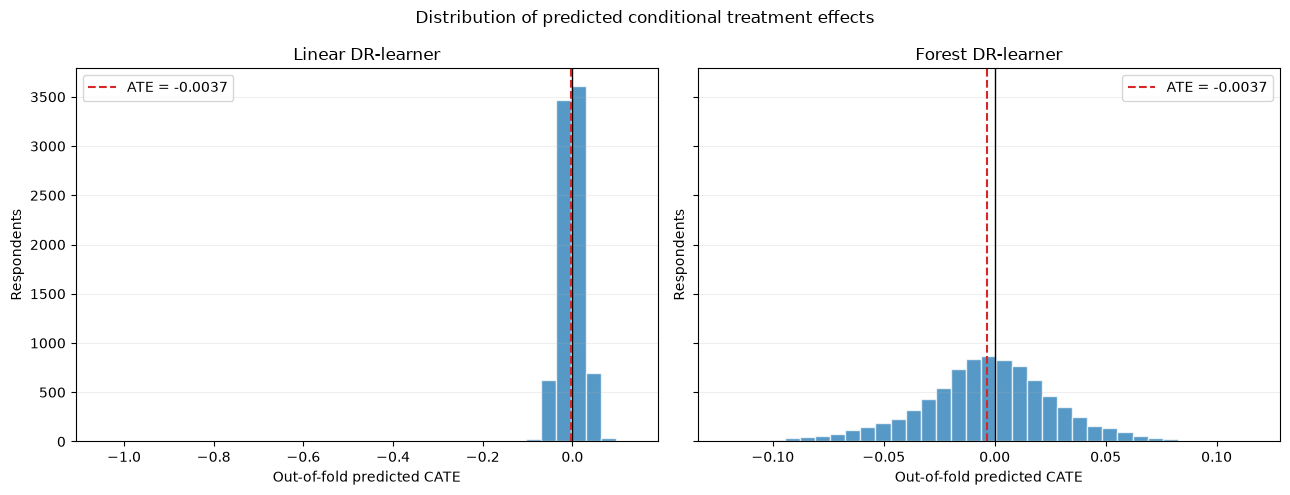

In [7]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    sharey=True,
)

for ax, variable, title in [
    (
        axes[0],
        "cate_linear_oof",
        "Linear DR-learner",
    ),
    (
        axes[1],
        "cate_forest_oof",
        "Forest DR-learner",
    ),
]:
    ax.hist(
        analysis[variable],
        bins=35,
        color="tab:blue",
        alpha=0.75,
        edgecolor="white",
    )

    ax.axvline(
        0,
        color="black",
        linewidth=1,
    )

    ax.axvline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=f"ATE = {OVERALL_ATE:.4f}",
    )

    ax.set_title(title)
    ax.set_xlabel("Out-of-fold predicted CATE")
    ax.set_ylabel("Respondents")
    ax.legend()
    ax.grid(axis="y", alpha=0.20)

fig.suptitle(
    "Distribution of predicted conditional treatment effects"
)

plt.tight_layout()
plt.show()

In [8]:
def cate_calibration_table(
    frame,
    prediction_column,
    number_of_groups=5,
):
    work = frame[
        [prediction_column, "dr_primary"]
    ].copy()

    # Ranking avoids problems if many predictions are tied.
    work["_rank"] = (
        work[prediction_column]
        .rank(method="first")
    )

    work["CATE_group"] = pd.qcut(
        work["_rank"],
        q=number_of_groups,
        labels=[
            f"Q{group}"
            for group in range(
                1,
                number_of_groups + 1,
            )
        ],
    )

    table = (
        work
        .groupby(
            "CATE_group",
            observed=True,
        )
        .agg(
            n=("dr_primary", "size"),
            mean_predicted_CATE=(
                prediction_column,
                "mean",
            ),
            mean_DR_pseudo_effect=(
                "dr_primary",
                "mean",
            ),
            sd_DR_pseudo_effect=(
                "dr_primary",
                "std",
            ),
        )
        .reset_index()
    )

    table["se_DR_mean"] = (
        table["sd_DR_pseudo_effect"]
        / np.sqrt(table["n"])
    )

    table["ci_lower"] = (
        table["mean_DR_pseudo_effect"]
        - 1.96 * table["se_DR_mean"]
    )

    table["ci_upper"] = (
        table["mean_DR_pseudo_effect"]
        + 1.96 * table["se_DR_mean"]
    )

    return table


linear_calibration = cate_calibration_table(
    analysis,
    "cate_linear_oof",
)

forest_calibration = cate_calibration_table(
    analysis,
    "cate_forest_oof",
)

print("LINEAR DR-LEARNER CALIBRATION")
display(linear_calibration.round(5))

print("FOREST DR-LEARNER CALIBRATION")
display(forest_calibration.round(5))

LINEAR DR-LEARNER CALIBRATION


,CATE_group,n,mean_predicted_CATE,mean_DR_pseudo_effect,sd_DR_pseudo_effect,se_DR_mean,ci_lower,ci_upper
0,Q1,1694,-0.04208,-0.01280,0.51123,0.01242,-0.03714,0.01155
1,Q2,1693,-0.01547,0.00275,0.66483,0.01616,-0.02892,0.03442
2,Q3,1693,-0.00241,0.00611,0.60967,0.01482,-0.02293,0.03515
3,Q4,1693,0.01047,-0.00551,0.46291,0.01125,-0.02756,0.01654
4,Q5,1694,0.03166,-0.00899,0.53259,0.01294,-0.03435,0.01637


FOREST DR-LEARNER CALIBRATION


,CATE_group,n,mean_predicted_CATE,mean_DR_pseudo_effect,sd_DR_pseudo_effect,se_DR_mean,ci_lower,ci_upper
0,Q1,1694,-0.04751,0.01204,0.67331,0.01636,-0.02002,0.04411
1,Q2,1693,-0.01694,-0.00750,0.54293,0.01320,-0.03336,0.01836
2,Q3,1693,-0.00255,-0.00683,0.51385,0.01249,-0.03130,0.01765
3,Q4,1693,0.01154,-0.00142,0.47699,0.01159,-0.02414,0.02130
4,Q5,1694,0.03731,-0.01474,0.57708,0.01402,-0.04223,0.01274


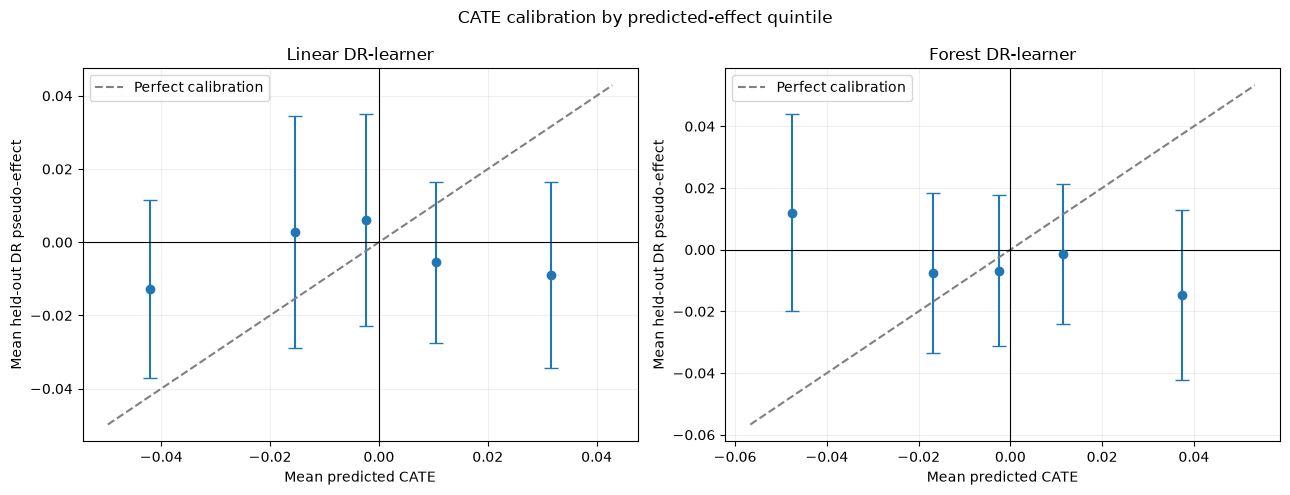

In [9]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

for ax, table, title in [
    (
        axes[0],
        linear_calibration,
        "Linear DR-learner",
    ),
    (
        axes[1],
        forest_calibration,
        "Forest DR-learner",
    ),
]:
    lower_error = (
        table["mean_DR_pseudo_effect"]
        - table["ci_lower"]
    )

    upper_error = (
        table["ci_upper"]
        - table["mean_DR_pseudo_effect"]
    )

    ax.errorbar(
        table["mean_predicted_CATE"],
        table["mean_DR_pseudo_effect"],
        yerr=[
            lower_error,
            upper_error,
        ],
        fmt="o",
        capsize=5,
        color="tab:blue",
    )

    combined_values = np.concatenate([
        table["mean_predicted_CATE"],
        table["ci_lower"],
        table["ci_upper"],
    ])

    plot_min = combined_values.min()
    plot_max = combined_values.max()
    padding = 0.10 * (plot_max - plot_min)

    ax.plot(
        [
            plot_min - padding,
            plot_max + padding,
        ],
        [
            plot_min - padding,
            plot_max + padding,
        ],
        color="gray",
        linestyle="--",
        label="Perfect calibration",
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8,
    )

    ax.set_title(title)
    ax.set_xlabel("Mean predicted CATE")
    ax.set_ylabel("Mean held-out DR pseudo-effect")
    ax.legend()
    ax.grid(alpha=0.20)

fig.suptitle(
    "CATE calibration by predicted-effect quintile"
)

plt.tight_layout()
plt.show()

In [10]:
def subgroup_cate_summary(
    frame,
    subgroup,
):
    work = frame[
        [
            subgroup,
            "dr_primary",
            "cate_linear_oof",
            "cate_forest_oof",
        ]
    ].copy()

    work[subgroup] = (
        work[subgroup]
        .astype("string")
        .fillna("Missing")
    )

    summary = (
        work
        .groupby(
            subgroup,
            observed=True,
        )
        .agg(
            n=("dr_primary", "size"),
            observed_DR_mean=(
                "dr_primary",
                "mean",
            ),
            linear_CATE_mean=(
                "cate_linear_oof",
                "mean",
            ),
            forest_CATE_mean=(
                "cate_forest_oof",
                "mean",
            ),
            observed_DR_sd=(
                "dr_primary",
                "std",
            ),
        )
        .reset_index()
    )

    summary["observed_DR_se"] = (
        summary["observed_DR_sd"]
        / np.sqrt(summary["n"])
    )

    summary["observed_ci_lower"] = (
        summary["observed_DR_mean"]
        - 1.96 * summary["observed_DR_se"]
    )

    summary["observed_ci_upper"] = (
        summary["observed_DR_mean"]
        + 1.96 * summary["observed_DR_se"]
    )

    return summary


subgroups_to_report = [
    "sex",
    "earliest_arrest_before_18",
    "r_victim_of_bullying_12_18_years",
    "race_ethnicity",
]

subgroup_tables = {}

for subgroup in subgroups_to_report:
    table = subgroup_cate_summary(
        analysis,
        subgroup,
    )

    subgroup_tables[subgroup] = table

    print(f"\n{subgroup.upper()}")
    display(table.round(5))


SEX


,sex,n,observed_DR_mean,linear_CATE_mean,forest_CATE_mean,observed_DR_sd,observed_DR_se,observed_ci_lower,observed_ci_upper
0,1,4311,-0.01311,-0.01285,-0.01186,0.53295,0.00812,-0.02902,0.00280
1,2,4156,0.00609,0.00606,0.00491,0.58819,0.00912,-0.01180,0.02397



EARLIEST_ARREST_BEFORE_18


,earliest_arrest_before_18,n,observed_DR_mean,linear_CATE_mean,forest_CATE_mean,observed_DR_sd,observed_DR_se,observed_ci_lower,observed_ci_upper
0,0,6955,0.00039,0.00055,-0.00039,0.53898,0.00646,-0.01228,0.01306
1,1,1512,-0.02245,-0.02251,-0.01856,0.65169,0.01676,-0.05530,0.01040



R_VICTIM_OF_BULLYING_12_18_YEARS


,r_victim_of_bullying_12_18_years,n,observed_DR_mean,linear_CATE_mean,forest_CATE_mean,observed_DR_sd,observed_DR_se,observed_ci_lower,observed_ci_upper
0,0.0,6010,-0.00742,-0.00737,-0.00770,0.55614,0.00717,-0.02148,0.00664
1,1.0,865,0.01032,0.01145,0.01937,0.79340,0.02698,-0.04256,0.06319
2,Missing,1592,0.00280,0.00264,-0.00079,0.40408,0.01013,-0.01704,0.02265



RACE_ETHNICITY


,race_ethnicity,n,observed_DR_mean,linear_CATE_mean,forest_CATE_mean,observed_DR_sd,observed_DR_se,observed_ci_lower,observed_ci_upper
0,Asian,142,0.02155,0.02210,-0.01046,0.32886,0.02760,-0.03254,0.07564
1,Black,2228,-0.00090,-0.00084,-0.00256,0.52845,0.01120,-0.02284,0.02105
2,Hispanic,1812,-0.00797,-0.00808,-0.00685,0.52608,0.01236,-0.03219,0.01625
3,Other,172,0.01260,0.01004,0.00081,0.56206,0.04286,-0.07140,0.09660
4,White,4113,-0.00487,-0.00451,-0.00274,0.59788,0.00932,-0.02314,0.01340


In [11]:
# These final fits use all observations and are suitable for
# generating CATE predictions for the analysis sample.
# Out-of-fold predictions should still be used for evaluation.

final_linear_model = make_linear_dr_learner()
final_linear_model.fit(
    X_cate,
    analysis["dr_primary"],
)

final_forest_model = make_forest_dr_learner(
    random_state=2026
)

final_forest_model.fit(
    X_cate,
    analysis["dr_primary"],
)

linear_feature_names = (
    final_linear_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

linear_coefficients = (
    final_linear_model
    .named_steps["regressor"]
    .coef_
)

linear_coefficient_table = pd.DataFrame({
    "feature": linear_feature_names,
    "coefficient": linear_coefficients,
})

linear_coefficient_table[
    "absolute_coefficient"
] = linear_coefficient_table[
    "coefficient"
].abs()

linear_coefficient_table = (
    linear_coefficient_table
    .sort_values(
        "absolute_coefficient",
        ascending=False,
    )
    .reset_index(drop=True)
)

print(
    "Linear-model intercept: "
    f"{final_linear_model.named_steps['regressor'].intercept_:.6f}"
)

print(
    "\nNumeric coefficients correspond approximately to "
    "a one-standard-deviation increase. Categorical "
    "coefficients are relative to the omitted reference level."
)

display(
    linear_coefficient_table.round(6)
)

Linear-model intercept: 0.017892

Numeric coefficients correspond approximately to a one-standard-deviation increase. Categorical coefficients are relative to the omitted reference level.


,feature,coefficient,absolute_coefficient
0,categorical__race_ethnicity_Hispanic,-0.036285,0.036285
1,categorical__race_ethnicity_Black,-0.031249,0.031249
2,numeric__missingindicator_teachers_good,-0.030359,0.030359
3,categorical__race_ethnicity_White,-0.028098,0.028098
4,categorical__earliest_arrest_before_18_1,-0.020456,0.020456
5,categorical__sex_2,0.017163,0.017163
6,categorical__r_victim_of_bullying_12_18_years_1.0,0.016765,0.016765
7,numeric__log_household_net_worth,-0.015033,0.015033
8,categorical__race_ethnicity_Other,-0.012440,0.012440
9,categorical__r_victim_of_bullying_12_18_years_...,0.009707,0.009707


In [12]:
if SAVE_OUTPUTS:
    respondent_output = analysis[
        [
            ID_COL,
            TREATMENT,
            OUTCOME,
            "dr_primary",
            "cate_linear_oof",
            "cate_forest_oof",
        ]
    ].copy()

    respondent_output.to_csv(
        OUTPUT_DIR
        / "cate_respondent_level_estimates.csv",
        index=False,
    )

    model_comparison.to_csv(
        OUTPUT_DIR
        / "cate_model_comparison.csv",
        index=False,
    )

    linear_calibration.to_csv(
        OUTPUT_DIR
        / "cate_linear_calibration.csv",
        index=False,
    )

    forest_calibration.to_csv(
        OUTPUT_DIR
        / "cate_forest_calibration.csv",
        index=False,
    )

    linear_coefficient_table.to_csv(
        OUTPUT_DIR
        / "cate_linear_coefficients.csv",
        index=False,
    )

    for subgroup, table in subgroup_tables.items():
        table.to_csv(
            OUTPUT_DIR
            / f"cate_subgroup_{subgroup}.csv",
            index=False,
        )

    print(f"Saved CATE outputs to: {OUTPUT_DIR}")

Saved CATE outputs to: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization/Causal Inference/model_outputs
